In [1]:
import snapatac2 as snap
import os
import sys
import scanpy as sc
import pandas as pd 
import anndata as ad
import scvi

/home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
import snapatac2 as snap
import anndata as ad

bm = snap.pp.import_fragments(
    "/mnt/claw-raid/elliot/P002_mtscATAC-seq/data/raw/bm_epilepsy/outs/fragments.tsv.gz",
    chrom_sizes=snap.genome.hg38,
    sorted_by_barcode=False,
)

brain = snap.pp.import_fragments(
    "/mnt/claw-raid/elliot/P002_mtscATAC-seq/data/raw/brain_epilepsy/data/outs/fragments.tsv.gz",
    chrom_sizes=snap.genome.hg38,
    sorted_by_barcode=False,
)

bm.obs["Sample"] = "BM"
bm.obs["Tissue"] = "bone_marrow"

brain.obs["Sample"] = "Brain"
brain.obs["Tissue"] = "brain"

data = ad.concat(
    [bm, brain],
    label="Sample",
    keys=["BM", "Brain"],
    index_unique="-",
)

# Now save the combined object
data.write("bm_brain_epilepsy.h5ad")

/home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
... storing 'Tissue' as categorical


2026-10-21 16:00:47 - INFO - Computing fragment size distribution...
2026-10-21 16:01:26 - INFO - Chromium init'ed with kwargs {}
2026-10-21 16:01:26 - INFO - Found chromium path: /home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/choreographer/cli/browser_exe/chrome-linux64/chrome
2026-10-21 16:01:26 - INFO - Temp directory created: /tmp/tmp6hgl7ew8.
2026-10-21 16:01:26 - INFO - Opening browser.
2026-10-21 16:01:26 - INFO - Temp directory created: /tmp/tmph9zwq2o5.
2026-10-21 16:01:26 - INFO - Temporary directory at: /tmp/tmph9zwq2o5
2026-10-21 16:01:27 - INFO - Conforming 1 to file:///tmp/tmp6hgl7ew8/index.html
2026-10-21 16:01:27 - INFO - Waiting on all navigates
2026-10-21 16:01:29 - INFO - All navigates done, putting them all in queue.
2026-10-21 16:01:29 - INFO - Getting tab from queue (has 1)
2026-10-21 16:01:29 - INFO - Got 2650
2026-10-21 16:01:29 - INFO - Processing fig.png
2026-10-21 16:01:29 - INFO - Sending big command for fig.png.
2026-10-21 16:01:29

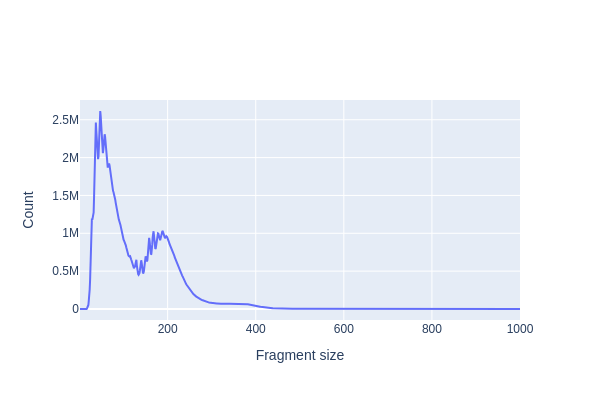

In [7]:
import copy
from anndata.tests.helpers import assert_equal

assert "reference_sequences" in bm.uns, "BM reference metadata is missing."
assert "reference_sequences" in brain.uns, "Brain reference metadata is missing."

# Verify both imports used the same reference sequences and ordering.
assert_equal(
    bm.uns["reference_sequences"],
    brain.uns["reference_sequences"],
)

# Restore only the missing metadata; do not replace existing metadata.
if "reference_sequences" not in data.uns:
    data.uns["reference_sequences"] = copy.deepcopy(
        bm.uns["reference_sequences"]
    )

snap.pl.frag_size_distr(data, interactive=False)

2026-10-21 16:01:30 - INFO - Chromium init'ed with kwargs {}
2026-10-21 16:01:30 - INFO - Found chromium path: /home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/choreographer/cli/browser_exe/chrome-linux64/chrome
2026-10-21 16:01:30 - INFO - Temp directory created: /tmp/tmpxh9yr7jz.
2026-10-21 16:01:30 - INFO - Opening browser.
2026-10-21 16:01:30 - INFO - Temp directory created: /tmp/tmpiv_0vq60.
2026-10-21 16:01:30 - INFO - Temporary directory at: /tmp/tmpiv_0vq60
2026-10-21 16:01:30 - INFO - Conforming 1 to file:///tmp/tmpxh9yr7jz/index.html
2026-10-21 16:01:30 - INFO - Waiting on all navigates
2026-10-21 16:01:33 - INFO - All navigates done, putting them all in queue.
2026-10-21 16:01:33 - INFO - Getting tab from queue (has 1)
2026-10-21 16:01:33 - INFO - Got 4784
2026-10-21 16:01:33 - INFO - Processing fig.png
2026-10-21 16:01:33 - INFO - Sending big command for fig.png.
2026-10-21 16:01:33 - INFO - Sent big command for fig.png.
2026-10-21 16:01:33 - INFO - 

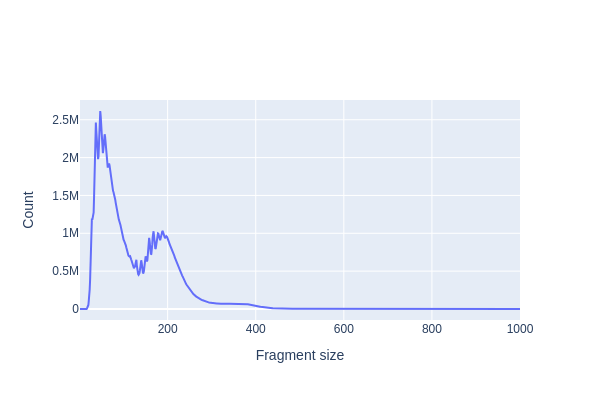

In [8]:
## Bit of extra information:
'''
1. Nucleosome-Free Region (NFR): The majority of fragments are short, typically around 80-300 base pairs (bp) in length. 
These short fragments represent regions of open chromatin where DNA is relatively accessible and not bound to nucleosomes. 
These regions are often referred to as nucleosome-free regions (NFRs) and correspond to regions of active transcriptional 
regulation.

2. Mono-Nucleosome Peaks: There is often a peak in the fragment size distribution at around 147-200 bp, 
which corresponds to the size of a single nucleosome wrapped DNA. These fragments result from the 
cutting of DNA by the transposase enzyme when it encounters a nucleosome, 
causing the DNA to be protected and resulting in fragments of the same size.

3. Di-Nucleosome Peaks: In addition to the mono-nucleosome peak, you may also observe 
a smaller peak at approximately 300-400 bp, corresponding to di-nucleosome fragments. 
These fragments occur when transposase cuts the DNA between two neighboring nucleosomes.

4. Large Fragments: Some larger fragments, greater than 500 bp in size, may be observed. 
These fragments can result from various sources, such as the presence of 
longer stretches of open chromatin or technical artifacts.
'''



snap.pl.frag_size_distr(data, interactive=False)

In [9]:
## Same plot with axis to log scale
fig = snap.pl.frag_size_distr(data, show=False)
fig.update_yaxes(type="log")
fig.show()

2026-10-21 16:01:33 - INFO - TemporaryDirectory.cleanup() worked.
2026-10-21 16:01:33 - INFO - shutil.rmtree worked.
2026-10-21 16:01:33 - INFO - TemporaryDirectory.cleanup() worked.
2026-10-21 16:01:33 - INFO - shutil.rmtree worked.


In [10]:
## TSS enrichment implies there is an increased accessibility or fragmentation of chromatin around the TSS
## Often indicative of promoter regions
snap.metrics.tsse(data, snap.genome.hg38)

2026-10-21 16:02:17 - INFO - Chromium init'ed with kwargs {}
2026-10-21 16:02:17 - INFO - Found chromium path: /home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/choreographer/cli/browser_exe/chrome-linux64/chrome
2026-10-21 16:02:17 - INFO - Temp directory created: /tmp/tmp90hyn1lo.
2026-10-21 16:02:17 - INFO - Opening browser.
2026-10-21 16:02:17 - INFO - Temp directory created: /tmp/tmpzfk1sqnp.
2026-10-21 16:02:17 - INFO - Temporary directory at: /tmp/tmpzfk1sqnp
2026-10-21 16:02:17 - INFO - Conforming 1 to file:///tmp/tmp90hyn1lo/index.html
2026-10-21 16:02:17 - INFO - Waiting on all navigates
2026-10-21 16:02:20 - INFO - All navigates done, putting them all in queue.
2026-10-21 16:02:20 - INFO - Getting tab from queue (has 1)
2026-10-21 16:02:20 - INFO - Got 7F80
2026-10-21 16:02:20 - INFO - Processing fig.png
2026-10-21 16:02:20 - INFO - Sending big command for fig.png.
2026-10-21 16:02:20 - INFO - Sent big command for fig.png.
2026-10-21 16:02:20 - INFO - 

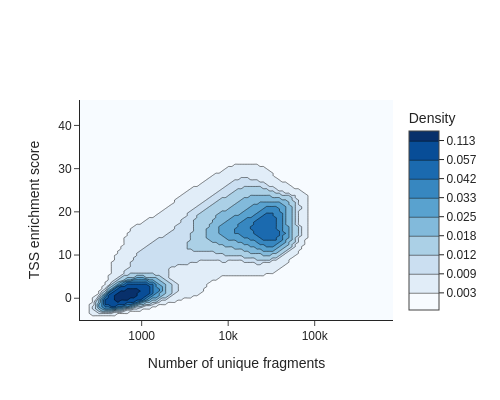

In [11]:
## To identify usable/high-quality cells, we can plot TSSe scores against number of unique fragments for each cell.
snap.pl.tsse(data, interactive=False)


##The cells in the upper right represent valid or high-quality cells, whereas those in the lower left represent low-quality 
# cells or empty droplets. Based on this plot, 
#we decided to set a minimum TSS enrichment of 10 and a minimum number of fragments of 5,000 to filter the cells.

In [12]:
## Oprion - Filtering cells here results in fewer mitochondrial variants deteced
snap.pp.filter_cells(data, min_counts=2000, min_tsse=4, max_counts=100000)
data

/home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


AnnData object with n_obs × n_vars = 10645 × 0
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'Sample', 'Tissue', 'tsse'
    uns: 'reference_sequences', 'frag_size_distr', 'library_tsse', 'frac_overlap_TSS', 'TSS_profile'
    obsm: 'fragment_paired'

In [13]:
## Cell by bin matrix containng insertion counts across 500bp bins across the genome
snap.pp.add_tile_matrix(data)

In [14]:
## Feature selection, which will be stored in data.var['selected'] this is particularly relevant for scrublet and spectral
## Selects most accessible features 
## n_features determines number of features, experiment with n_features to find the optimal number for your dataset
snap.pp.select_features(data, n_features=150000)

2026-10-21 16:03:17 - INFO - Selected 150000 features.


In [15]:
%%time
snap.pp.scrublet(data)
snap.pp.filter_doublets(data)
data

2026-10-21 16:03:25 - INFO - Simulating doublets...
2026-10-21 16:03:29 - INFO - Spectral embedding ...
2026-10-21 16:03:30 - INFO - TemporaryDirectory.cleanup() worked.
2026-10-21 16:03:30 - INFO - shutil.rmtree worked.
2026-10-21 16:06:53 - INFO - Calculating doublet scores...
2026-10-21 16:07:28 - INFO - Detected doublet rate = 2.527%


CPU times: user 27min 11s, sys: 13.1 s, total: 27min 24s
Wall time: 4min 21s


AnnData object with n_obs × n_vars = 10376 × 6062095
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'Sample', 'Tissue', 'tsse', 'doublet_probability', 'doublet_score'
    var: 'count', 'selected'
    uns: 'reference_sequences', 'frag_size_distr', 'library_tsse', 'frac_overlap_TSS', 'TSS_profile', 'scrublet_sim_doublet_score', 'doublet_rate'
    obsm: 'fragment_paired'

/home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
2026-10-21 16:11:00 - INFO - Chromium init'ed with kwargs {}
2026-10-21 16:11:00 - INFO - Found chromium path: /home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/choreographer/cli/browser_exe/chrome-linux64/chrome
2026-10-21 16:11:00 - INFO - Temp directory created: /tmp/tmpadpi1abe.
2026-10-21 16:11:00 - INFO - Opening browser.
2026-10-21 16:11:00 - INFO - Temp directory created: /tmp/tmpsesv09_s.
2026-10-21 16:11:00 - INFO - Temporary directory at: /tmp/tmpsesv09_s
2026-10-21 16:11:01 - INFO - Conforming 1 to file:///tmp/tmpadpi1abe/index.html
2026-10-21 16:11:01 - INFO - Waiting on all navigates
2026-10-21 16:11:03 - INFO - All navigates done, putting them all in queue.
2026-10-21 16:11:03 - INFO - Getting tab from queue (has 1)
2026-10-21 16:11:03 - INFO - Got F4A9

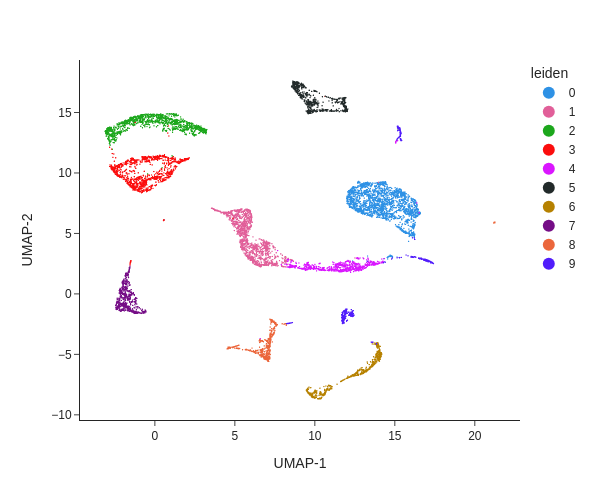

In [16]:
snap.tl.spectral(data)
snap.tl.umap(data) 
snap.pp.knn(data)
snap.tl.leiden(data, resolution=0.3)

snap.pl.umap(data, color='leiden', interactive=False, height=500)

In [23]:
%%time
gene_matrix = snap.pp.make_gene_matrix(data, snap.genome.hg38)
gene_matrix

CPU times: user 16min 1s, sys: 19.6 s, total: 16min 20s
Wall time: 57.4 s


AnnData object with n_obs × n_vars = 10290 × 60606
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'Sample', 'Tissue', 'tsse', 'doublet_probability', 'doublet_score', 'leiden'

In [24]:
import scanpy as sc

sc.pp.filter_genes(gene_matrix, min_cells= 5)
sc.pp.normalize_total(gene_matrix)
sc.pp.log1p(gene_matrix)

2026-10-21 12:54:12 - INFO - TemporaryDirectory.cleanup() worked.
2026-10-21 12:54:12 - INFO - shutil.rmtree worked.


In [25]:
sc.external.pp.magic(gene_matrix, solver="approximate")
gene_matrix.obsm["X_umap"] = data.obsm["X_umap"]


In [ ]:
marker_genes = ['MS4A1', 'CD3D', 'LEF1', 'NKG7', 'TREM1', 'LYZ', 'PPBP']
sc.pl.umap(gene_matrix, use_raw=False, color=["leiden"] + marker_genes)

In [47]:
import pandas as pd

top5_table = pd.DataFrame(
    [
        {
            "cluster": str(cluster),
            "rank": rank,
            "gene": gene,
            "mean_accessibility": value,
        }
        for cluster, row in mean_accessibility.iterrows()
        for rank, (gene, value) in enumerate(
            row.nlargest(5).items(),
            start=1,
        )
    ]
)

print(top5_table.round(3).to_string(index=False))

cluster  rank    gene  mean_accessibility
      0     1   RUNX1               2.189
      0     2     MBP               1.950
      0     3 COLEC12               1.378
      0     4    FLT1               1.267
      0     5    TCF4               1.260
      1     1   RUNX1               1.597
      1     2     MBP               1.438
      1     3   MECOM               1.392
      1     4     ERG               1.169
      1     5    SYT1               1.110
      2     1     MBP               2.046
      2     2   RUNX1               1.892
      2     3  SLC1A3               1.560
      2     4    FLT1               1.559
      2     5   CSF1R               1.484
      3     1     MBP               1.787
      3     2   RUNX1               1.671
      3     3  SLC1A3               1.461
      3     4    FLT1               1.334
      3     5    TCF4               1.286
      4     1   RUNX1               1.853
      4     2     MBP               1.663
      4     3   MECOM             

/home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


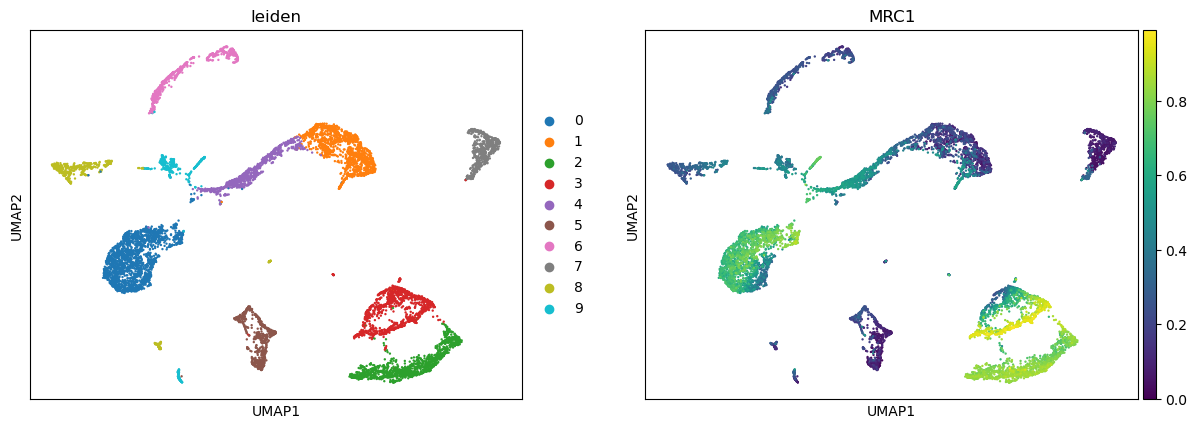

In [73]:
marker_genes = ['MRC1']
sc.pl.umap(gene_matrix, use_raw=False, color=["leiden"] + marker_genes)

2026-10-19 13:10:04 - INFO - Chromium init'ed with kwargs {}
2026-10-19 13:10:04 - INFO - Found chromium path: /home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/choreographer/cli/browser_exe/chrome-linux64/chrome
2026-10-19 13:10:04 - INFO - Temp directory created: /tmp/tmpqyf25lli.
2026-10-19 13:10:04 - INFO - Opening browser.
2026-10-19 13:10:04 - INFO - Temp directory created: /tmp/tmprwecmhot.


Sample                    BM  Brain
mtDNA_group                        
Microglia                 11   2630
Bone marrow cells       6659    394
non-immune brain cells     0    682


2026-10-19 13:10:05 - INFO - Temporary directory at: /tmp/tmprwecmhot
2026-10-19 13:10:05 - INFO - Conforming 1 to file:///tmp/tmpqyf25lli/index.html
2026-10-19 13:10:05 - INFO - Waiting on all navigates
2026-10-19 13:10:07 - INFO - All navigates done, putting them all in queue.
2026-10-19 13:10:07 - INFO - Getting tab from queue (has 1)
2026-10-19 13:10:07 - INFO - Got C6DB
2026-10-19 13:10:07 - INFO - Processing fig.png
2026-10-19 13:10:07 - INFO - Sending big command for fig.png.
2026-10-19 13:10:08 - INFO - Sent big command for fig.png.
2026-10-19 13:10:08 - INFO - Reloading tab C6DB before return.
2026-10-19 13:10:08 - INFO - Putting tab C6DB back (queue size: 0).
2026-10-19 13:10:08 - INFO - Waiting for all cleanups to finish.
2026-10-19 13:10:08 - INFO - Exiting Kaleido
2026-10-19 13:10:08 - INFO - Closing browser.
2026-10-19 13:10:08 - INFO - Closing browser.
2026-10-19 13:10:08 - INFO - TemporaryDirectory.cleanup() worked.
2026-10-19 13:10:08 - INFO - shutil.rmtree worked.
202

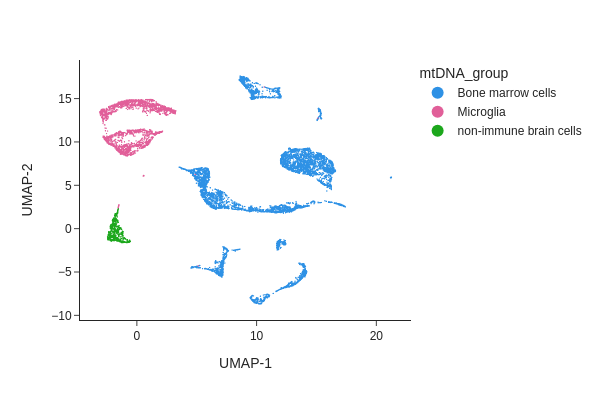

In [25]:
import pandas as pd

group_map = {
    "0":  "Bone marrow cells",
    "1":  "Bone marrow cells",
    "2":  "Microglia",
    "3":  "Microglia",
    "4":  "Bone marrow cells",
    "5":  "Bone marrow cells",  # T cells from either tissue
    "6":  "non-immune brain cells",
    "7":  "Bone marrow cells",
    "8":  "Bone marrow cells",
    "9":  "Bone marrow cells",
    "10": "Bone marrow cells",
    "11": "Bone marrow cells",
}

clusters = data.obs["leiden"].astype(str)
assert clusters.isin(group_map).all(), "Unmapped Leiden clusters present"

data.obs["mtDNA_group"] = pd.Categorical(
    clusters.map(group_map),
    categories=[
        "Microglia",
        "Bone marrow cells",
        "non-immune brain cells",
    ],
)

print(pd.crosstab(data.obs["mtDNA_group"], data.obs["Sample"]))

snap.pl.umap(data, color="mtDNA_group", interactive=False)

2026-10-05 17:04:24 - INFO - TemporaryDirectory.cleanup() worked.
2026-10-05 17:04:24 - INFO - shutil.rmtree worked.


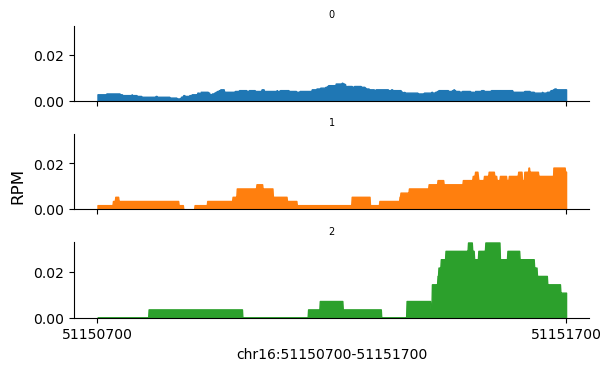

In [103]:
#Visualise accesibility of promoter regions of marker genes
snap.pl.coverage(data, region='chr16:51150700-51151700', groupby='leiden')


In [68]:
## Annotate the clusters and assign them to known cell types
## Compute gene activities for each cell using pp.make_gene_matrix

gene_matrix = snap.pp.make_gene_matrix(data, snap.genome.hg38)
gene_matrix

AnnData object with n_obs × n_vars = 1082 × 60606
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'tsse', 'doublet_probability', 'doublet_score', 'leiden', 'cell_type'

In [69]:
### The cell by gene activity matrix is sparse
## The MAGIC algorithm performs imputation and data smoothing
## Then scanpy does subsequent steps 
## First perform gene filtering, normalisation and transformation and then call MAGIC
sc.pp.filter_genes(gene_matrix, min_cells= 5)
sc.pp.normalize_total(gene_matrix)
sc.pp.log1p(gene_matrix)
# Skip MAGIC imputation - the analysis will work fine without it
sc.external.pp.magic(gene_matrix, solver="approximate")

# Copy over UMAP embedding
gene_matrix.obsm["X_umap"] = data.obsm["X_umap"]

2026-10-06 11:34:41 - INFO - TemporaryDirectory.cleanup() worked.
2026-10-06 11:34:41 - INFO - shutil.rmtree worked.


In [ ]:
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!    mtDNA VARIANT CALLING !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

In [75]:
import sys
import numpy as np
import pandas as pd
import anndata as ad

sys.path.insert(
    0,
    "/mnt/claw-raid/elliot/P002_mtscATAC-seq/scripts/"
    "Py_mTCall_tools/Py_mTCall_tools"
)
import variant_calling_fast as vc

folders = {
    "BM": "/mnt/claw-raid/elliot/P002_mtscATAC-seq/data/raw/bm_epilepsy/mgatk_output/final",
    "Brain": "/mnt/claw-raid/elliot/P002_mtscATAC-seq/data/raw/brain_epilepsy/data/mgatk_output/final",
}

results = {}

for sample, folder in folders.items():
    obs = data.obs.loc[data.obs["Sample"] == sample].copy()
    combined_names = obs.index.copy()
    suffix = f"-{sample}"

    assert all(str(name).endswith(suffix) for name in combined_names), (
        f"Unexpected barcode format for {sample}: "
        f"{combined_names[:5].tolist()}"
    )

    # Remove only the sample suffix added by ad.concat
    obs.index = pd.Index([
        str(name)[:-len(suffix)] for name in combined_names
    ])
    assert obs.index.is_unique

    # Only cell metadata is needed by your variant-calling function
    sample_data = ad.AnnData(obs=obs)

    sample_data = vc.process_variants_fast(
        folder,
        sample_data,
        verbose=True,
        coverage_threshold=10,
        min_strand_count=2,
    )

    sample_data.obs_names = combined_names
    results[sample] = sample_data

# Union of variant names across both samples
variant_names = list(dict.fromkeys(
    variant
    for result in results.values()
    for variant in result.uns["variant_names"]
))

variant_index = pd.Index(variant_names)

matrix_keys = [
    "variant_vaf",
    "variant_counts",
    "coverage_per_cell",
    "variant_confident",
]

# Assemble matrices in the exact cell order of your combined object
for key in matrix_keys:
    combined = np.full(
        (data.n_obs, len(variant_names)),
        np.nan,
        dtype=np.float32,
    )

    for sample, result in results.items():
        rows = data.obs_names.get_indexer(result.obs_names)
        cols = variant_index.get_indexer(result.uns["variant_names"])

        assert (rows >= 0).all()
        assert (cols >= 0).all()

        combined[np.ix_(rows, cols)] = np.asarray(
            result.obsm[key], dtype=np.float32
        )

    data.obsm[key] = combined

data.uns["variant_names"] = variant_names

# Keep sample-specific summaries separate
data.uns["variant_summary_by_sample"] = {}

for sample, result in results.items():
    summary = result.uns["variant_summary"].copy()
    summary.index = pd.Index(
        result.uns["variant_names"], name="variant"
    )
    data.uns["variant_summary_by_sample"][sample] = summary

data.obs["total_variant_count"] = np.nansum(
    data.obsm["variant_counts"], axis=1
)

mgatk = data

print("Combined cells:", mgatk.n_obs)
print("Union variants:", len(variant_names))
print(pd.crosstab(mgatk.obs["mtDNA_group"], mgatk.obs["Sample"]))

=== Fast Variant Calling Pipeline ===


You'll find variant names in adata.uns['variant_names']

Find coverage PER cell in adata.obsm['coverage_per_cell']

Variant summmary stats similar to Signac are in adata.uns['variant_summary']

Variant matrices are in adata.obsm["variant_vaf"]


=== IMPORTANT NOTE ===

Remember that variant VAFs are only included if they pass the min_strand_count filter

AND the coverage threshold if specified!



Loaded counts data: (132166, 7429)
Loaded coverage data: (115247831, 3)
Identifying variants (memory-optimized chunked method)...
Processing all 98962 variant observations (no artificial limits)
Integrating with AnnData...
=== Pipeline Complete ===
Processed 4556 variants in 6558 matching cells
=== Fast Variant Calling Pipeline ===


You'll find variant names in adata.uns['variant_names']

Find coverage PER cell in adata.obsm['coverage_per_cell']

Variant summmary stats similar to Signac are in adata.uns['variant_summary']

Variant matrices are in adata

KeyError: 'mtDNA_group'

CELLS PER GROUP
MG: 2623
BrainMG: 2615
BM: 6602
C7: 680

Labels require coverage >= 15.
Percentages use adequately covered cells as denominators.
MG = clusters 2/3; BrainMG = Brain cells in clusters 2/3.
MG and BM may overlap.
In plots, grey = missing VAF or insufficient coverage.

ELIGIBLE VARIANTS AT EACH VAF THRESHOLD
threshold
0.010    7
0.020    7
0.030    7
0.040    7
0.050    5
0.075    4
0.100    2
0.125    1
0.150    1
0.200    1
0.250    1

=== zero_C7_labels ===
  variant  threshold  MG_n  BrainMG_n  BM_n  C7_n  C7_covered   C7_max  C7_q99  MG_minus_C7_pct
T-14488-C      0.050    11         11     6     0         459 0.047619     0.0         0.655152
A-15924-G      0.075     6          6    11     0         514 0.000000     0.0         0.314136
G-16390-A      0.050     6          6     4     0         519 0.038710     0.0         0.313972
 T-4248-C      0.100     5          5     9     0         502 0.083333     0.0         0.270709

=== C7_max_at_most_0.05 ===
  variant  th

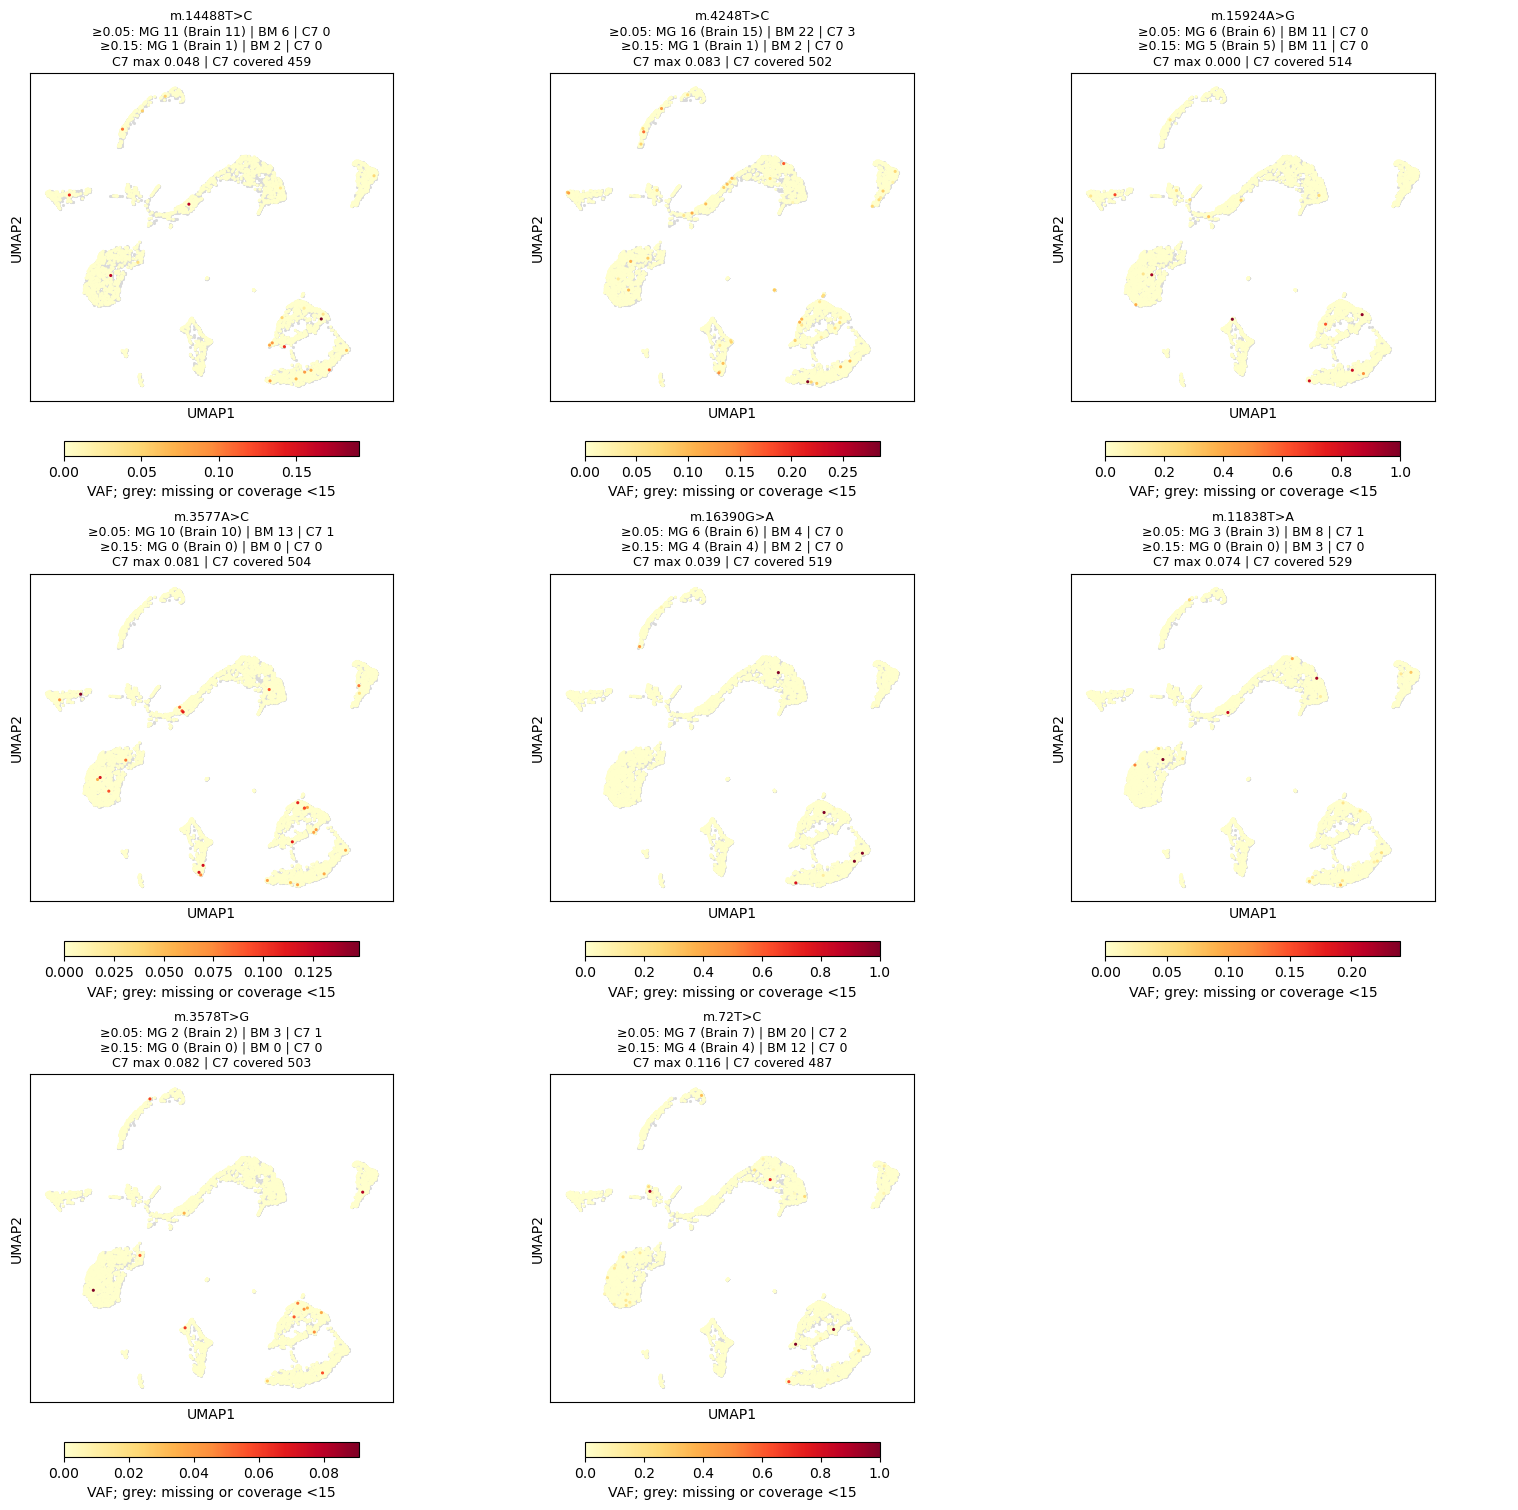

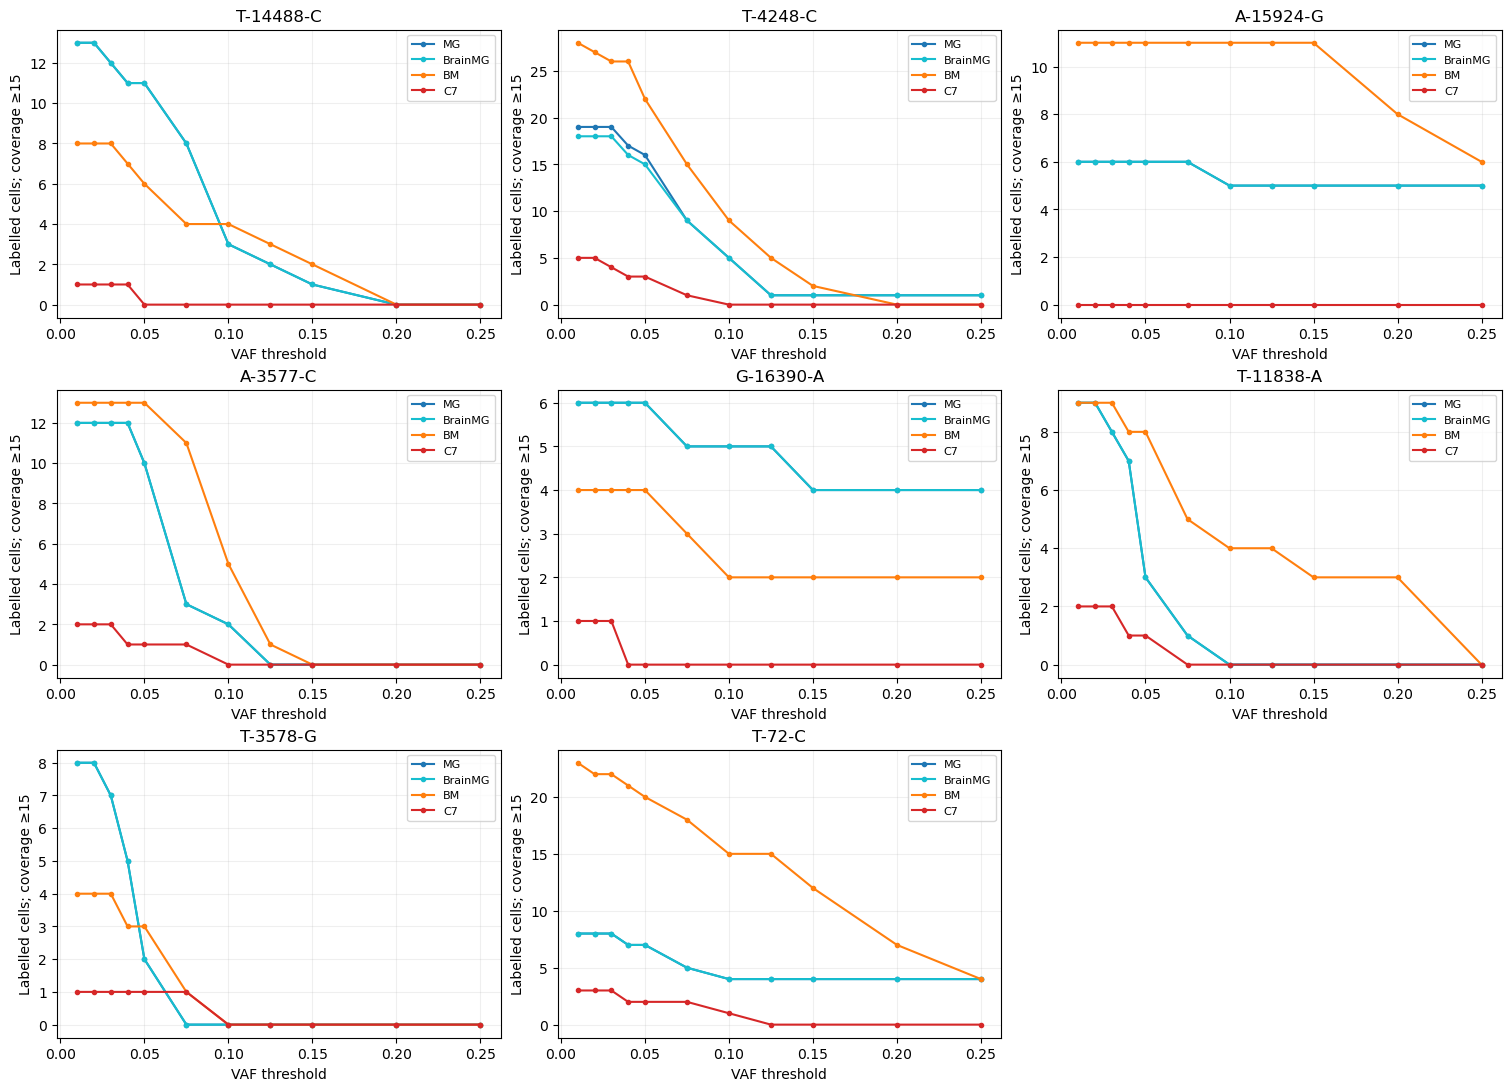

In [147]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# SETTINGS
# ============================================================

MIN_COVERAGE = 15

VAF_THRESHOLDS = [
    0.01, 0.02, 0.03, 0.04, 0.05,
    0.075, 0.10, 0.125, 0.15, 0.20, 0.25
]

MIN_BM = 3
MIN_MG = 5
MAX_C7_LABELLED_PCT = 5.0
MIN_C7_COVERED = 1  # Increase to require more measured negative-control cells

N_PER_STRATEGY = 6
MAX_VARIANTS_TO_PLOT = 30
PANELS_PER_PAGE = 9

SAVE_OUTPUT = True
OUTDIR = Path("variant_exploration_cov15")

if SAVE_OUTPUT:
    OUTDIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# DATA AND GROUPS
# ============================================================

clusters = mgatk.obs["leiden"].astype(str)
samples = mgatk.obs["Sample"].astype(str)

groups = {
    "MG": clusters.isin(["2", "3"]).to_numpy(),
    "BrainMG": (
        samples.eq("Brain") & clusters.isin(["2", "3"])
    ).to_numpy(),
    "BM": samples.eq("BM").to_numpy(),
    "C7": clusters.eq("7").to_numpy()
}

for group, mask in groups.items():
    if not mask.any():
        raise ValueError(f"No cells in group {group}")

names = np.asarray(mgatk.uns["variant_names"]).astype(str)
name_to_col = {name: j for j, name in enumerate(names)}
umap = np.asarray(mgatk.obsm["X_umap"])

vaf = np.asarray(mgatk.obsm["variant_vaf"])
coverage = np.asarray(mgatk.obsm["coverage_per_cell"])

if vaf.shape != coverage.shape:
    raise ValueError("VAF and coverage matrices have different shapes.")

if vaf.shape != (mgatk.n_obs, len(names)):
    raise ValueError("VAF dimensions do not match cells and variant names.")

valid = (
    np.isfinite(vaf) &
    np.isfinite(coverage) &
    (coverage >= MIN_COVERAGE)
)

print("CELLS PER GROUP")
for group, mask in groups.items():
    print(f"{group}: {mask.sum()}")

print(f"\nLabels require coverage >= {MIN_COVERAGE}.")
print("Percentages use adequately covered cells as denominators.")
print("MG = clusters 2/3; BrainMG = Brain cells in clusters 2/3.")
print("MG and BM may overlap.")
print("In plots, grey = missing VAF or insufficient coverage.")

# ============================================================
# COVERAGE-AWARE SUMMARIES
# ============================================================

base = pd.DataFrame({"variant": names})

for group, mask in groups.items():
    group_valid = valid[mask]
    group_vaf = vaf[mask]
    n_covered = group_valid.sum(axis=0)

    sums = np.where(group_valid, group_vaf, 0).sum(
        axis=0, dtype=np.float64
    )
    maxima = np.where(
        group_valid, group_vaf, -np.inf
    ).max(axis=0)
    maxima[n_covered == 0] = np.nan

    base[f"{group}_covered"] = n_covered
    base[f"{group}_mean"] = np.divide(
        sums, n_covered,
        out=np.full(len(names), np.nan),
        where=n_covered > 0
    )
    base[f"{group}_max"] = maxima
    base[f"{group}_positive_any"] = (
        group_valid & (group_vaf > 0)
    ).sum(axis=0)

c7_masked = np.where(
    valid[groups["C7"]], vaf[groups["C7"]], np.nan
)
has_c7_coverage = base["C7_covered"].to_numpy() > 0

for quantile, column in [(0.99, "C7_q99"), (0.95, "C7_q95")]:
    values = np.full(len(names), np.nan)
    if has_c7_coverage.any():
        values[has_c7_coverage] = np.nanquantile(
            c7_masked[:, has_c7_coverage], quantile, axis=0
        )
    base[column] = values

del c7_masked

# ============================================================
# ADAPTIVE BACKGROUND COUNTS
# ============================================================

adaptive_definitions = [
    ("C7_max", 0.0),
    ("C7_max", 0.02),
    ("C7_q99", 0.02)
]

for background_name, margin in adaptive_definitions:
    suffix = f"above_{background_name}_plus_{margin:.2f}"
    cutoff = np.maximum(
        base[background_name].to_numpy() + margin, 0.02
    )

    for group in ["MG", "BrainMG", "BM"]:
        mask = groups[group]
        base[f"{group}_{suffix}"] = (
            valid[mask] & (vaf[mask] > cutoff[None, :])
        ).sum(axis=0)

# ============================================================
# FIXED-THRESHOLD SEARCH
# ============================================================

tables = []

for threshold in VAF_THRESHOLDS:
    table = base.copy()
    table["threshold"] = threshold

    for group, mask in groups.items():
        counts = (
            valid[mask] & (vaf[mask] >= threshold)
        ).sum(axis=0)
        denominators = base[f"{group}_covered"].to_numpy()

        table[f"{group}_n"] = counts
        table[f"{group}_pct"] = np.divide(
            100.0 * counts, denominators,
            out=np.full(len(names), np.nan),
            where=denominators > 0
        )

    table["MG_minus_C7_pct"] = table["MG_pct"] - table["C7_pct"]
    table["BrainMG_minus_C7_pct"] = (
        table["BrainMG_pct"] - table["C7_pct"]
    )
    table["MG_to_C7_rate_ratio"] = (
        (table["MG_n"] + 0.5) / (table["MG_covered"] + 1)
    ) / (
        (table["C7_n"] + 0.5) / (table["C7_covered"] + 1)
    )

    table["eligible"] = (
        (table["MG_n"] >= MIN_MG) &
        (table["BrainMG_n"] >= 1) &
        (table["BM_n"] >= MIN_BM) &
        (table["C7_covered"] >= MIN_C7_COVERED) &
        (table["C7_pct"] <= MAX_C7_LABELLED_PCT) &
        (table["MG_minus_C7_pct"] > 0)
    )

    tables.append(table)

sweep = pd.concat(tables, ignore_index=True)
eligible = sweep[sweep["eligible"]].copy()

print("\nELIGIBLE VARIANTS AT EACH VAF THRESHOLD")
print(
    eligible.groupby("threshold")["variant"].nunique()
    .reindex(VAF_THRESHOLDS, fill_value=0)
    .to_string()
)

# ============================================================
# COMPLEMENTARY RANKINGS
# ============================================================

def choose(table, columns, ascending):
    return (
        table.sort_values(columns, ascending=ascending)
        .drop_duplicates("variant")
        .head(N_PER_STRATEGY)
        .copy()
    )

strategies = {}

strategies["zero_C7_labels"] = choose(
    eligible[eligible["C7_n"] == 0],
    ["MG_n", "threshold", "BM_n"],
    [False, False, False]
)

for cap in [0.05, 0.10, 0.15]:
    strategies[f"C7_max_at_most_{cap:.2f}"] = choose(
        eligible[eligible["C7_max"] <= cap],
        ["MG_n", "threshold", "BM_n"],
        [False, False, False]
    )

strategies["up_to_3_C7_labels"] = choose(
    eligible[eligible["C7_n"] <= 3],
    ["MG_n", "C7_n", "threshold", "BM_n"],
    [False, True, False, False]
)

strategies["largest_MG_rate_excess"] = choose(
    eligible,
    ["MG_minus_C7_pct", "threshold", "BM_n"],
    [False, False, False]
)

strategies["most_Brain_microglia"] = choose(
    eligible,
    ["BrainMG_n", "C7_pct", "threshold", "BM_n"],
    [False, True, False, False]
)

strategies["stronger_BM_support"] = choose(
    eligible[
        (eligible["BM_n"] >= 10) &
        (eligible["C7_n"] <= 5)
    ],
    ["MG_n", "threshold", "BM_n"],
    [False, False, False]
)

for background_name, margin in adaptive_definitions:
    suffix = f"above_{background_name}_plus_{margin:.2f}"

    adaptive = base[
        (base[f"MG_{suffix}"] >= MIN_MG) &
        (base[f"BrainMG_{suffix}"] >= 1) &
        (base[f"BM_{suffix}"] >= MIN_BM) &
        (base["C7_covered"] >= MIN_C7_COVERED)
    ].sort_values(
        [f"MG_{suffix}", f"BM_{suffix}"],
        ascending=[False, False]
    ).head(N_PER_STRATEGY)

    adaptive_names = adaptive["variant"].tolist()

    # Fixed 0.05 counts are for display only in these strategies.
    display = sweep[
        np.isclose(sweep["threshold"], 0.05) &
        sweep["variant"].isin(adaptive_names)
    ].copy()

    if len(display):
        display = (
            display.set_index("variant")
            .reindex(adaptive_names)
            .reset_index()
        )

    strategies[f"adaptive_{suffix}"] = display

# ============================================================
# COLLECT CANDIDATES AND SAVE TABLES
# ============================================================

display_columns = [
    "variant", "threshold",
    "MG_n", "BrainMG_n", "BM_n", "C7_n",
    "C7_covered", "C7_max", "C7_q99",
    "MG_minus_C7_pct"
]

all_choices = []

for strategy, table in strategies.items():
    print(f"\n=== {strategy} ===")

    if table.empty:
        print("No matches")
        continue

    print(table[display_columns].to_string(index=False))

    if strategy.startswith("adaptive_"):
        suffix = strategy.removeprefix("adaptive_")
        print("Adaptive counts; threshold 0.05 above is display only:")
        print(table[[
            "variant",
            f"MG_{suffix}",
            f"BrainMG_{suffix}",
            f"BM_{suffix}"
        ]].to_string(index=False))

    tagged = table.copy()
    tagged["strategy"] = strategy
    all_choices.append(tagged)

if SAVE_OUTPUT:
    sweep.to_csv(OUTDIR / "all_threshold_results.csv", index=False)
    base.to_csv(OUTDIR / "background_summaries.csv", index=False)

if not all_choices:
    print("\nNo candidates passed these settings.")

else:
    choices = pd.concat(all_choices, ignore_index=True)

    strategy_summary = choices.groupby("variant").agg(
        strategies=(
            "strategy",
            lambda x: "; ".join(dict.fromkeys(x))
        ),
        n_strategies=("strategy", "nunique")
    )

    ordered_names = []
    for rank in range(N_PER_STRATEGY):
        for table in strategies.values():
            if rank < len(table):
                variant = table.iloc[rank]["variant"]
                if variant not in ordered_names:
                    ordered_names.append(variant)

    ordered_names = ordered_names[:MAX_VARIANTS_TO_PLOT]

    print("\nCANDIDATES SELECTED FOR PLOTTING")
    print(strategy_summary.reindex(ordered_names).to_string())

    candidate_counts = sweep[
        sweep["variant"].isin(ordered_names)
    ][display_columns].copy()

    if SAVE_OUTPUT:
        choices.to_csv(
            OUTDIR / "strategy_candidates.csv", index=False
        )
        candidate_counts.to_csv(
            OUTDIR / "candidate_threshold_counts.csv", index=False
        )
        strategy_summary.reindex(ordered_names).to_csv(
            OUTDIR / "plotted_candidate_strategies.csv"
        )

    # ========================================================
    # UMAP PAGES
    # Grey cells have missing VAF or coverage below the cutoff.
    # Covered cells retain their original VAF, including zeros.
    # ========================================================

    for start in range(0, len(ordered_names), PANELS_PER_PAGE):
        page_names = ordered_names[start:start + PANELS_PER_PAGE]
        ncols = min(3, len(page_names))
        nrows = int(np.ceil(len(page_names) / ncols))

        fig, axes = plt.subplots(
            nrows, ncols,
            figsize=(5.2 * ncols, 5 * nrows),
            sharex=True, sharey=True,
            squeeze=False,
            constrained_layout=True
        )

        for ax, variant in zip(axes.flat, page_names):
            j = name_to_col[variant]
            values = vaf[:, j]
            usable = valid[:, j]
            usable_idx = np.flatnonzero(usable)
            order = usable_idx[np.argsort(values[usable_idx])]

            ax.scatter(
                umap[:, 0], umap[:, 1],
                c="#d9d9d9",
                s=5, linewidths=0,
                rasterized=True
            )

            vmax = (
                max(float(values[usable].max()), 0.001)
                if usable.any() else 1.0
            )

            sc = ax.scatter(
                umap[order, 0], umap[order, 1],
                c=values[order],
                cmap="YlOrRd",
                vmin=0, vmax=vmax,
                s=5, linewidths=0,
                rasterized=True
            )

            counts = {}
            for threshold in [0.05, 0.15]:
                positive = usable & (values >= threshold)
                counts[threshold] = {
                    group: int(positive[mask].sum())
                    for group, mask in groups.items()
                }

            a = counts[0.05]
            b = counts[0.15]
            background = base.iloc[j]
            ref, position, alt = variant.upper().split("-")

            ax.set_title(
                f"m.{position}{ref}>{alt}\n"
                f"≥0.05: MG {a['MG']} (Brain {a['BrainMG']}) | "
                f"BM {a['BM']} | C7 {a['C7']}\n"
                f"≥0.15: MG {b['MG']} (Brain {b['BrainMG']}) | "
                f"BM {b['BM']} | C7 {b['C7']}\n"
                f"C7 max {background['C7_max']:.3f} | "
                f"C7 covered {int(background['C7_covered'])}",
                fontsize=9
            )

            ax.set_xlabel("UMAP1")
            ax.set_ylabel("UMAP2")
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_aspect("equal")

            fig.colorbar(
                sc, ax=ax,
                orientation="horizontal",
                fraction=0.045, pad=0.06,
                label=f"VAF; grey: missing or coverage <{MIN_COVERAGE}"
            )

        for ax in axes.flat[len(page_names):]:
            ax.axis("off")

        page_number = start // PANELS_PER_PAGE + 1

        if SAVE_OUTPUT:
            fig.savefig(
                OUTDIR / f"candidate_umaps_page_{page_number}.png",
                dpi=220, bbox_inches="tight"
            )

        plt.show()
        plt.close(fig)

    # ========================================================
    # THRESHOLD-RESPONSE PLOTS
    # ========================================================

    response_names = ordered_names[:9]
    ncols = min(3, len(response_names))
    nrows = int(np.ceil(len(response_names) / ncols))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(5 * ncols, 3.6 * nrows),
        squeeze=False,
        constrained_layout=True
    )

    colours = {
        "MG": "tab:blue",
        "BrainMG": "tab:cyan",
        "BM": "tab:orange",
        "C7": "tab:red"
    }

    for ax, variant in zip(axes.flat, response_names):
        subset = sweep[
            sweep["variant"] == variant
        ].sort_values("threshold")

        for group, colour in colours.items():
            ax.plot(
                subset["threshold"],
                subset[f"{group}_n"],
                marker="o", markersize=3,
                color=colour, label=group
            )

        ax.set_title(variant)
        ax.set_xlabel("VAF threshold")
        ax.set_ylabel(f"Labelled cells; coverage ≥{MIN_COVERAGE}")
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)

    for ax in axes.flat[len(response_names):]:
        ax.axis("off")

    if SAVE_OUTPUT:
        fig.savefig(
            OUTDIR / "threshold_response.png",
            dpi=220, bbox_inches="tight"
        )

    plt.show()
    plt.close(fig)